# R-KalWeNN no YearPredictionMSD

Mesmo modelo e mesmas definições do notebook 06, aplicados ao
YearPredictionMSD. As diferenças em relação ao House Prices estão todas na
seção 1 e na seção 3.

| seção | conteúdo |
|---|---|
| 1 | configuração |
| 2 | definições: thermometer, médias, endereçamento, ReW, R-KalWeNN |
| 3 | dados: carga, divisão do UCI e análise |
| 4 | R-KalWeNN: `c`, `y` e a atualização de cada um |
| 5 | avaliação vetorizada |
| 6 | grid search |
| 7 | a ReW na configuração vencedora |
| 8 | endereços ocupados por RAM node |
| 9 | resultado |

**Três diferenças em relação ao notebook 06.** Não há baseline publicado: a
tese do Lusquino cobre `calcofi`, `houseprice`, `kdd` e `parkison`, e não este
dataset, então a comparação é R-KalWeNN contra ReW e contra os chutes triviais.
O alvo é o ano de lançamento e não passa por `log1p`. E a divisão de treino e
teste é a prescrita pelo UCI, descrita na seção 3.2, e não um `train_test_split`
embaralhado.

---
# Seção 1 — Configuração

In [1]:
import os
import time
import zipfile
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from itertools import product
from sklearn.metrics import mean_absolute_error, mean_squared_error

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 9, "axes.grid": True, "grid.alpha": .25,
    "axes.spines.top": False, "axes.spines.right": False,
})
COR_KAL, COR_REW, COR_REF = "#2F6B6A", "#B4674D", "#8A8F98"

# ── dados ────────────────────────────────────────────────────────────────────
URL_UCI   = "https://archive.ics.uci.edu/static/public/203/yearpredictionmsd.zip"
URL_ALT   = ("https://archive.ics.uci.edu/ml/machine-learning-databases/"
             "00203/YearPredictionMSD.txt.zip")
ARQ_ZIP   = "YearPredictionMSD.zip"
ARQ_TXT   = "YearPredictionMSD.txt"

# Divisão prescrita pelo UCI, ver seção 3.2. NÃO é embaralhada.
N_TREINO_UCI = 463715
N_TESTE_UCI  = 51630

# Quantos exemplos de treino usar. None = todos.
# Com 463.715 exemplos um único ajuste leva dezenas de segundos, e o grid
# inteiro passa de dez horas. Subamostrar é o que torna a busca viável.
SUBAMOSTRA_TREINO = None
SEED_SUBAMOSTRA   = 0

# ── codificação ──────────────────────────────────────────────────────────────
SEED_MAPPING = 0

print(f"UCI: {N_TREINO_UCI:,} treino + {N_TESTE_UCI:,} teste = "
      f"{N_TREINO_UCI + N_TESTE_UCI:,} exemplos, 90 atributos")
print(f"subamostra do treino: {SUBAMOSTRA_TREINO if SUBAMOSTRA_TREINO else 'nenhuma'}")

UCI: 463,715 treino + 51,630 teste = 515,345 exemplos, 90 atributos
subamostra do treino: nenhuma


---
# Seção 2 — Definições

## 2.1 Codificação: thermometer simples

É o `ThermometerEncoder` do projeto de classificação, em
`KalWeNN/wisard/encoder.py`, e não o `DynamicThermometer` do `wisardpkg` que o
notebook 06 usa.

O valor é primeiro **cortado** na faixa $[\min, \max]$ do treino, depois
convertido num nível inteiro

$$
k = \left\lfloor \frac{x - \min}{\max - \min + \varepsilon}\, n \right\rfloor,
\qquad k \in [0, n]
$$

e os $k$ primeiros bits são ligados. Assim $x = \min$ dá o vetor todo zero e
$x = \max$ dá o vetor todo um.

Duas diferenças em relação ao `DynamicThermometer`. Este **corta** valores fora
da faixa do treino, em vez de deixá-los saturar por conta própria, o que importa
porque o teste pode ter valores fora do intervalo visto no treino. E a
comparação é por nível inteiro e não por limiar com `>` estrito, o que muda o
tratamento das bordas.

In [2]:
class ThermometerEncoder:
    """Porte do encoder do projeto de classificação (KalWeNN/wisard/encoder.py)."""

    def __init__(self, minimum, maximum, resolution):
        self.minimum, self.maximum, self.resolution = minimum, maximum, resolution
        self._range = (maximum - minimum) + 1e-9

    def encode(self, column):
        col = np.clip(column, self.minimum, self.maximum)
        k = np.clip(((col - self.minimum) / self._range * self.resolution).astype(int),
                    0, self.resolution)
        return (np.arange(self.resolution) < k[:, np.newaxis]).astype(np.uint8)


def build_encoders(X, resolution):
    mins, maxs = X.min(axis=0), X.max(axis=0)
    return [ThermometerEncoder(mins[j], maxs[j], resolution) for j in range(X.shape[1])]


def apply_encoders(X, encoders):
    return np.concatenate([enc.encode(X[:, j]) for j, enc in enumerate(encoders)], axis=1)


print("ThermometerEncoder definido")

ThermometerEncoder definido


---
## 2.2 As médias

Duas famílias, porque as duas células guardam coisas diferentes.

**Família ReW.** A célula guarda contador $c_k$ e soma $S_k$. A estimativa da
RAM node é $\mu_k = S_k / c_k$, e o contador entra como **denominador**.

| média | fórmula |
|---|---|
| `SimpleMean` | $\sum_k S_k \big/ \sum_k c_k$ |
| `PowerMean(p)` | $\left(\frac{1}{m}\sum \mu_k^{\,p}\right)^{1/p}$ |
| `HarmonicMean` | $m \big/ \sum \mu_k^{-1}$ |
| `HarmonicPower(p)` | $\left(m \big/ \sum \mu_k^{-p}\right)^{1/p}$ |
| `ExponentialMean` | $\log\!\left(\frac{1 + \sum e^{\mu_k}}{m}\right)$ |
| `Median` | valor central dos $\mu_k$, pela fórmula da tese |

$m$ é o número de RAM nodes com $c_k \neq 0$. O `1 +` da `ExponentialMean` está
no código da referência (`double emean = 1`) e é mantido. A `Median` é o porte
do `Median::calculate` do `wisardpkg`, que é o que a tese executou.

**Família R-KalWeNN.** A célula guarda uma confiança $c_k \in [0,1)$ e um valor
esperado $y_k$. O $y_k$ já é a estimativa local, então não há divisão por
contador: o $c_k$ **multiplica** o $y_k$, e a normalização é $\sum c_k$.

O prefixo `K` marca que são as fórmulas ponderadas que desenhamos para o
R-KalWeNN, e não as da Regression WiSARD.

| média | fórmula |
|---|---|
| `K-SimpleMean` | $\dfrac{\sum c_k y_k}{\sum c_k}$ |
| `K-PowerMean(p)` | $\left(\dfrac{\sum c_k y_k^{\,p}}{\sum c_k}\right)^{1/p}$ |
| `K-HarmonicMean` | $\dfrac{\sum c_k}{\sum c_k / y_k}$ |
| `K-HarmonicPower(p)` | $\left(\dfrac{\sum c_k}{\sum c_k / y_k^{\,p}}\right)^{1/p}$ |
| `K-ExponentialMean` | $\log\!\left(\dfrac{\sum c_k e^{y_k}}{\sum c_k}\right)$ |
| `K-Median` | $y$ onde o $c$ acumulado cruza $\tfrac{1}{2}\sum c_k$ |

Onde a ReW divide por $c_k$, aqui multiplica. O $\sum c_k$ no denominador é o
que impede o resultado de encolher: sem ele, multiplicar por $c_k < 1$ puxaria
a predição para baixo do valor esperado.

Duas diferenças deliberadas em relação à família ReW. Só entram células com
evidência, em vez de passar $[0,0]$ e cada média filtrar. E o `1 +` da
exponencial foi retirado, porque não tem lugar numa forma normalizada por
$\sum c_k$.

`GeometricMean` e `LogisticMean` ficaram de fora das duas famílias. A geométrica
acumula um produto de $\mu_k \approx 12$ sobre as RAM nodes e estoura o `double`
com mais de 285 delas; a logística devolve sempre um valor em $(0,1)$, e o alvo
vale 12.

Harmônica e harmônica-potência exigem $y_k > 0$. Com o alvo em `log1p` isso
vale sempre, e a condição está escrita no código.

In [3]:
# ─────────────────────────── família ReW ─────────────────────────────────────
class Mean:
    """`output_rams` é uma lista de [contador, soma_y], incluindo as RAM nodes
    não visitadas como [0, 0], como no predict da referência."""
    nome = "Mean"
    def calculate(self, output_rams):
        raise NotImplementedError
    def __repr__(self):
        return f"ReW.{self.nome}"


class SimpleMean(Mean):
    nome = "SimpleMean"
    def calculate(self, output_rams):
        sc = sum(c for c, _ in output_rams)
        sy = sum(y for _, y in output_rams)
        return sy / sc if sc > 0 else 0.0


class PowerMean(Mean):
    def __init__(self, power=2):
        self.power = power; self.nome = f"PowerMean({power})"
    def calculate(self, output_rams):
        s, m = 0.0, 0
        for c, y in output_rams:
            if c != 0:
                s += (y / c) ** self.power; m += 1
        return (s / m) ** (1.0 / self.power) if m > 0 else 0.0


class HarmonicMean(Mean):
    nome = "HarmonicMean"
    def calculate(self, output_rams):
        s, m = 0.0, 0
        for c, y in output_rams:
            if c != 0:
                mu = y / c
                if mu != 0:
                    s += 1.0 / mu; m += 1
        return m / s if m > 0 else 0.0


class HarmonicPowerMean(Mean):
    def __init__(self, power=2):
        self.power = power; self.nome = f"HarmonicPower({power})"
    def calculate(self, output_rams):
        s, m = 0.0, 0
        for c, y in output_rams:
            if c != 0:
                mu = y / c
                if mu != 0:
                    s += 1.0 / (mu ** self.power); m += 1
        return (m / s) ** (1.0 / self.power) if m > 0 else 0.0


class ExponentialMean(Mean):
    nome = "ExponentialMean"
    def calculate(self, output_rams):
        e, m = 1.0, 0                          # começa em 1, como na referência
        for c, y in output_rams:
            if c != 0:
                e += np.exp(y / c); m += 1
        return float(np.log(e / m)) if m > 0 else 0.0


class Median(Mean):
    """Porte do Median::calculate do wisardpkg, que é o que a tese executou.

    Divide sem checar contador zero, ao contrário das outras médias, e usa
    índice deslocado em um. Onde a referência leria fora do vetor, aqui devolve
    NaN em vez de ler lixo de memória, e os NaN vão para o fim da ordenação.
    """
    nome = "Median"
    def calculate(self, output_rams):
        mus = [np.divide(float(y), float(c)) if c != 0 else float("nan")
               for c, y in output_rams]
        mus = sorted(mus, key=lambda v: (np.isnan(v), v))
        n = len(mus)
        if n % 2 == 0:
            i = n // 2
            return (mus[i] + mus[i + 1]) / 2.0 if i + 1 < n else float("nan")
        i = (n - 1) // 2 + 1
        return mus[i] if i < n else float("nan")


def medias_rew():
    return {"SimpleMean": SimpleMean(), "PowerMean(2)": PowerMean(2),
            "HarmonicMean": HarmonicMean(), "HarmonicPower(2)": HarmonicPowerMean(2),
            "ExponentialMean": ExponentialMean(), "Median": Median()}


print("médias da família ReW:", ", ".join(medias_rew()))

médias da família ReW: SimpleMean, PowerMean(2), HarmonicMean, HarmonicPower(2), ExponentialMean, Median


In [4]:
# ────────────────────── família R-KalWeNN (ponderadas) ───────────────────────
class MediaK:
    """`pares` é uma lista de (c_k, y_k) das células COM evidência.

    c_k é confiança em [0,1), y_k é o valor esperado local.
    Todas normalizam por sum(c), o que mantém o resultado na escala do alvo.
    """
    nome = "MediaK"
    def calculate(self, pares):
        raise NotImplementedError
    def __repr__(self):
        return self.nome


class KSimpleMean(MediaK):
    nome = "K-SimpleMean"
    def calculate(self, pares):
        sc = sum(c for c, _ in pares)
        return sum(c * y for c, y in pares) / sc if sc > 0 else np.nan


class KPowerMean(MediaK):
    def __init__(self, power=2):
        self.power = power; self.nome = f"K-PowerMean({power})"
    def calculate(self, pares):
        sc = sum(c for c, _ in pares)
        if sc <= 0:
            return np.nan
        return (sum(c * y ** self.power for c, y in pares) / sc) ** (1.0 / self.power)


class KHarmonicMean(MediaK):
    nome = "K-HarmonicMean"
    def calculate(self, pares):
        sc = s = 0.0
        for c, y in pares:
            if y > 0:
                sc += c; s += c / y
        return sc / s if s > 0 else np.nan


class KHarmonicPowerMean(MediaK):
    def __init__(self, power=2):
        self.power = power; self.nome = f"K-HarmonicPower({power})"
    def calculate(self, pares):
        sc = s = 0.0
        for c, y in pares:
            if y > 0:
                sc += c; s += c / y ** self.power
        return (sc / s) ** (1.0 / self.power) if s > 0 else np.nan


class KExponentialMean(MediaK):
    nome = "K-ExponentialMean"
    def calculate(self, pares):
        sc = sum(c for c, _ in pares)
        if sc <= 0:
            return np.nan
        return float(np.log(sum(c * np.exp(y) for c, y in pares) / sc))


class KMedian(MediaK):
    """Mediana ponderada: y onde o c acumulado cruza metade de sum(c)."""
    nome = "K-Median"
    def calculate(self, pares):
        pares = sorted(pares, key=lambda t: t[1])
        total = sum(c for c, _ in pares)
        if total <= 0:
            return np.nan
        meio, acum = total / 2.0, 0.0
        for c, y in pares:
            acum += c
            if acum >= meio:
                return y
        return pares[-1][1]


def medias_kal():
    """Prefixo K: fórmulas ponderadas, desenhadas para o R-KalWeNN.

    Não são as da Regression WiSARD, que estão em `medias_rew()`."""
    return {"K-SimpleMean": KSimpleMean(), "K-PowerMean(2)": KPowerMean(2),
            "K-HarmonicMean": KHarmonicMean(),
            "K-HarmonicPower(2)": KHarmonicPowerMean(2),
            "K-ExponentialMean": KExponentialMean(), "K-Median": KMedian()}


print("médias da família R-KalWeNN:", ", ".join(medias_kal()))

médias da família R-KalWeNN: K-SimpleMean, K-PowerMean(2), K-HarmonicMean, K-HarmonicPower(2), K-ExponentialMean, K-Median


---
## 2.2 Endereçamento

In [5]:
class Retina:
    """Converte entrada binarizada em endereços, um por RAM node."""

    def __init__(self, address_size, mapping):
        self.address_size = int(address_size)
        self.mapping = np.asarray(mapping, dtype=int).reshape(-1, self.address_size)
        self.n_rams = self.mapping.shape[0]
        self.n_addr = 1 << self.address_size
        self._pesos = 1 << np.arange(self.address_size)     # LSB primeiro

    def enderecos(self, Xb):
        """(n, retina) uint8 -> (n, n_rams) int."""
        Xb = np.asarray(Xb, dtype=np.uint8)
        return (Xb[:, self.mapping] * self._pesos).sum(axis=2).astype(np.int64)


def sorteia_mapping(retina_bits, address_size, seed=0):
    """Permutação dos bits da retina, truncada a um múltiplo de address_size."""
    n_rams = retina_bits // address_size
    rng = np.random.default_rng(seed)
    return rng.permutation(retina_bits)[: n_rams * address_size].tolist()


print("Retina definida")

Retina definida


---
## 2.3 Regression WiSARD

Serve de comparação para o R-KalWeNN, com a mesma binarização, o mesmo
`mapping` e a mesma divisão. Cada família de média fica com o seu modelo: a ReW
usa as médias da seção 2.2 sem prefixo, o R-KalWeNN usa as `K-`.

In [6]:
class RegressionWiSARD:
    """Regression WiSARD. Recebe entrada já binarizada."""

    def __init__(self, address_size, mean, mapping):
        self.retina = Retina(address_size, mapping)
        self.mean = mean

    @property
    def n_rams_(self):
        return self.retina.n_rams

    def fit(self, Xb, y):
        y = np.asarray(y, dtype=float)
        addr = self.retina.enderecos(Xb)
        self._mem = [dict() for _ in range(self.n_rams_)]
        for i in range(len(y)):
            for r_ in range(self.n_rams_):
                cel = self._mem[r_].get(addr[i, r_])
                if cel is None:
                    self._mem[r_][addr[i, r_]] = [1.0, y[i]]
                else:
                    cel[0] += 1.0; cel[1] += y[i]
        return self

    def predict(self, Xb):
        addr = self.retina.enderecos(Xb)
        vazia = [0.0, 0.0]
        return np.array([
            self.mean.calculate([self._mem[r_].get(addr[i, r_], vazia)
                                 for r_ in range(self.n_rams_)])
            for i in range(len(addr))])

    def memoria_bytes(self):
        return sum(len(m) for m in self._mem) * 24    # chave + 2 floats


print("RegressionWiSARD definida")

RegressionWiSARD definida


---
# Seção 3 — Dados

## 3.1 Carga

O arquivo tem 515.345 linhas e 91 colunas: a primeira é o ano de lançamento, as
outras 90 são atributos de timbre, sendo 12 médias e 78 covariâncias. São cerca
de 450 MB comprimidos.

A carga usa `float32` nos atributos, o que reduz a memória de 371 MB para 185 MB
e cabe com folga. A resolução do `float32` é de sete dígitos decimais, bem acima
da granularidade que o thermometer usa.

In [7]:
if not os.path.exists(ARQ_TXT):
    if not os.path.exists(ARQ_ZIP):
        print(f"baixando de {URL_UCI} ...")
        try:
            urllib.request.urlretrieve(URL_UCI, ARQ_ZIP)
        except Exception as e:
            print(f"  falhou ({e}), tentando a URL alternativa")
            urllib.request.urlretrieve(URL_ALT, ARQ_ZIP)
    print("descompactando ...")
    with zipfile.ZipFile(ARQ_ZIP) as z:
        nome = [n for n in z.namelist() if n.endswith(".txt")][0]
        with z.open(nome) as origem, open(ARQ_TXT, "wb") as destino:
            destino.write(origem.read())

t0 = time.perf_counter()
dados = pd.read_csv(ARQ_TXT, header=None, dtype=np.float32)
print(f"lido em {time.perf_counter()-t0:.0f} s: {dados.shape[0]:,} linhas x "
      f"{dados.shape[1]} colunas")

y_todos = dados.iloc[:, 0].values.astype(np.float64)     # ano
X_todos = dados.iloc[:, 1:].values                       # 90 atributos
del dados

print(f"alvo (ano): {y_todos.min():.0f} a {y_todos.max():.0f}")
print(f"atributos : {X_todos.shape[1]}, memória {X_todos.nbytes/1e6:.0f} MB")

baixando de https://archive.ics.uci.edu/static/public/203/yearpredictionmsd.zip ...
descompactando ...
lido em 14 s: 515,345 linhas x 91 colunas
alvo (ano): 1922 a 2011
atributos : 90, memória 186 MB


## 3.2 Divisão de treino e teste, como o UCI prescreve

A página do dataset no UCI dá uma instrução explícita:

> You should respect the following train / test split: train: first 463,715
> examples, test: last 51,630 examples. It avoids the "producer effect" by
> making sure no song from a given artist ends up in both the train and test
> set.

O motivo é o **efeito produtor**. Músicas do mesmo artista, do mesmo álbum ou
do mesmo produtor compartilham características de timbre que vêm da produção e
não do ano. Se duas faixas do mesmo disco caírem uma no treino e outra no
teste, o modelo acerta o ano por reconhecer o disco, não por aprender a relação
entre timbre e época. O resultado fica otimista e não generaliza.

O arquivo já vem ordenado de forma que essa divisão por posição separa os
artistas. Por isso a divisão é **por posição e sem embaralhar**, ao contrário
do notebook 06, que usa `train_test_split` com `random_state=0`.

Consequência prática para nós: não existe sorteio na divisão, então ela não é
fonte de variação. A única aleatoriedade dos experimentos é o `mapping` e a
ordem de apresentação no treino.

In [8]:
X_train = X_todos[:N_TREINO_UCI]
y_train = y_todos[:N_TREINO_UCI]
X_test  = X_todos[N_TREINO_UCI:N_TREINO_UCI + N_TESTE_UCI]
y_test  = y_todos[N_TREINO_UCI:N_TREINO_UCI + N_TESTE_UCI]

if SUBAMOSTRA_TREINO is not None and SUBAMOSTRA_TREINO < len(X_train):
    sel = np.random.default_rng(SEED_SUBAMOSTRA).choice(
        len(X_train), SUBAMOSTRA_TREINO, replace=False)
    sel.sort()                      # mantém a ordem original do arquivo
    X_train, y_train = X_train[sel], y_train[sel]
    print(f"treino subamostrado para {len(X_train):,} exemplos")

N_TREINO, N_ATRIB = len(X_train), X_train.shape[1]
print(f"treino {N_TREINO:,}   teste {len(X_test):,}   atributos {N_ATRIB}")
print(f"anos no treino: {y_train.min():.0f} a {y_train.max():.0f}")
print(f"anos no teste : {y_test.min():.0f} a {y_test.max():.0f}")

treino 463,715   teste 51,630   atributos 90
anos no treino: 1922 a 2011
anos no teste : 1927 a 2010


## 3.3 O alvo

O ano de lançamento é fortemente concentrado nos anos 2000, o que define o que é
um erro bom neste dataset: se a maior parte das músicas está numa faixa estreita,
chutar essa faixa já acerta bastante. Os chutes triviais entram como referência
por isso.

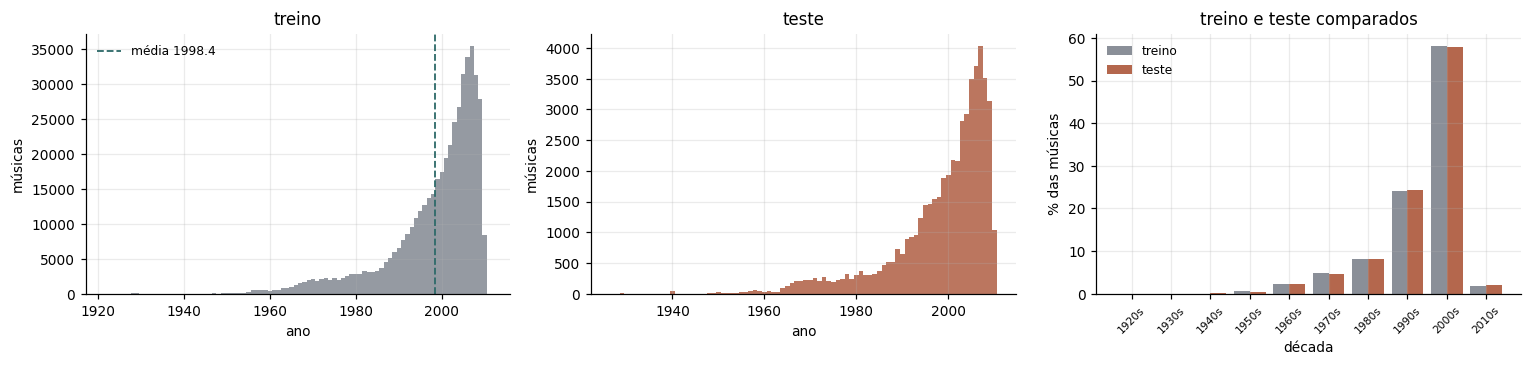

ALVO

  treino: 1922 a 2011, média 1998.39, mediana 2002, desvio 10.94
  teste : 1927 a 2010, média 1998.50, mediana 2002, desvio 10.85

  concentração no treino:
    de 1990 a 2011: 84.0%
    de 2000 a 2011: 59.8%
    de 2005 a 2011: 36.3%

REFERÊNCIAS (erro em anos)

  chutar a média do treino   : MAE 8.1131   RMSE 10.8525
  chutar a mediana do treino : MAE 7.5878

  variância do alvo no treino: 119.68   desvio 10.94


In [14]:
mae_media   = mean_absolute_error(y_test, np.full(len(y_test), y_train.mean()))
mae_mediana = mean_absolute_error(y_test, np.full(len(y_test), np.median(y_train)))
rmse_media  = float(np.sqrt(mean_squared_error(y_test, np.full(len(y_test), y_train.mean()))))

fig, ax = plt.subplots(1, 3, figsize=(14, 3.4))
ax[0].hist(y_train, bins=np.arange(y_train.min(), y_train.max() + 2) - .5,
           color=COR_REF, alpha=.9)
ax[0].axvline(y_train.mean(), color=COR_KAL, ls="--", lw=1.2,
              label=f"média {y_train.mean():.1f}")
ax[0].set(xlabel="ano", ylabel="músicas", title="treino")
ax[0].legend(frameon=False, fontsize=8)

ax[1].hist(y_test, bins=np.arange(y_test.min(), y_test.max() + 2) - .5,
           color=COR_REW, alpha=.9)
ax[1].set(xlabel="ano", ylabel="músicas", title="teste")

dec_tr = (y_train // 10 * 10).astype(int)
dec_te = (y_test // 10 * 10).astype(int)
d = sorted(set(dec_tr) | set(dec_te))
ptr = [100 * (dec_tr == x).mean() for x in d]
pte = [100 * (dec_te == x).mean() for x in d]
x = np.arange(len(d))
ax[2].bar(x - .2, ptr, width=.4, color=COR_REF, label="treino")
ax[2].bar(x + .2, pte, width=.4, color=COR_REW, label="teste")
ax[2].set(xticks=x, xticklabels=[f"{v}s" for v in d], xlabel="década",
          ylabel="% das músicas", title="treino e teste comparados")
ax[2].tick_params(axis="x", labelrotation=45, labelsize=7)
ax[2].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

print("ALVO\n")
print(f"  treino: {y_train.min():.0f} a {y_train.max():.0f}, média {y_train.mean():.2f}, "
      f"mediana {np.median(y_train):.0f}, desvio {y_train.std():.2f}")
print(f"  teste : {y_test.min():.0f} a {y_test.max():.0f}, média {y_test.mean():.2f}, "
      f"mediana {np.median(y_test):.0f}, desvio {y_test.std():.2f}")
q = [50, 80, 90, 95, 99]
print(f"\n  concentração no treino:")
for lo, hi in [(1990, 2011), (2000, 2011), (2005, 2011)]:
    print(f"    de {lo} a {hi}: {100*((y_train>=lo)&(y_train<=hi)).mean():.1f}%")

print("\nREFERÊNCIAS (erro em anos)\n")
print(f"  chutar a média do treino   : MAE {mae_media:.4f}   RMSE {rmse_media:.4f}")
print(f"  chutar a mediana do treino : MAE {mae_mediana:.4f}")
print(f"\n  variância do alvo no treino: {y_train.var():.2f}   desvio {y_train.std():.2f}")

## 3.4 A escala dos 90 atributos

São 12 médias de timbre e 78 covariâncias, e as duas famílias têm ordem de
grandeza diferente. Isso importa direto para a binarização, porque o thermometer
define os limiares pelo mínimo e pelo máximo de cada atributo **no treino**.

Um atributo com cauda longa tem quase todos os valores comprimidos nos primeiros
níveis, e os níveis de cima ficam vazios. A tabela abaixo mede quantos níveis
cada atributo de fato usa, para uma dada resolução, o que é a quantidade de
informação que ele consegue passar para a retina.

 atributo       mínimo       máximo        faixa  níveis usados   p1-p99 / faixa
--------------------------------------------------------------------------------
        0        1.749       61.970       60.221             21            0.467
        1     -337.092      384.066      721.158             20            0.356
        2     -301.005      322.851      623.857             21            0.293
        3     -154.184      289.527      443.711             19            0.197
        4     -181.953      262.069      444.022             20            0.257
        5      -81.794      119.816      201.610             20            0.307
      ...
       87     -236.039      463.419      699.459             17            0.104
       88    -7458.378     7393.398    14851.776             18            0.070
       89     -318.223      600.766      918.990             17            0.137

NÍVEIS USADOS, com resolução 20

  mínimo 13, mediana 19, máximo 21
  atributos que usam menos da 

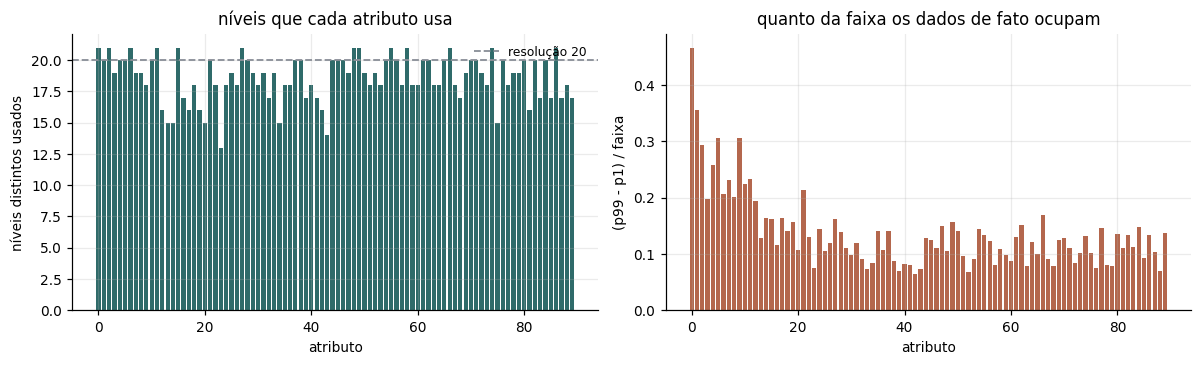

In [10]:
RES_DIAG = 20          # resolução usada só neste diagnóstico

mins, maxs = X_train.min(axis=0), X_train.max(axis=0)
faixa = maxs - mins
print(f"{'atributo':>9}{'mínimo':>13}{'máximo':>13}{'faixa':>13}"
      f"{'níveis usados':>15}{'p1-p99 / faixa':>17}")
print("-" * 80)
usados, conc = [], []
for j in range(N_ATRIB):
    k = np.clip(((X_train[:, j] - mins[j]) / (faixa[j] + 1e-9) * RES_DIAG).astype(int),
                0, RES_DIAG)
    usados.append(len(np.unique(k)))
    p1, p99 = np.percentile(X_train[:, j], [1, 99])
    conc.append((p99 - p1) / (faixa[j] + 1e-9))
    if j < 6 or j >= N_ATRIB - 3:
        print(f"{j:>9}{mins[j]:>13.3f}{maxs[j]:>13.3f}{faixa[j]:>13.3f}"
              f"{usados[-1]:>15}{conc[-1]:>17.3f}")
    elif j == 6:
        print(f"{'...':>9}")
usados, conc = np.array(usados), np.array(conc)

print(f"\nNÍVEIS USADOS, com resolução {RES_DIAG}\n")
print(f"  mínimo {usados.min()}, mediana {int(np.median(usados))}, máximo {usados.max()}")
print(f"  atributos que usam menos da metade dos níveis: "
      f"{(usados < RES_DIAG/2).sum()} de {N_ATRIB}")
print(f"\nCONCENTRAÇÃO  (faixa entre os percentis 1 e 99, dividida pela faixa total)\n")
print(f"  mediana {np.median(conc):.3f}")
print(f"  atributos em que 98% dos dados ocupam menos de 20% da faixa: "
      f"{(conc < 0.2).sum()} de {N_ATRIB}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].bar(np.arange(N_ATRIB), usados, color=COR_KAL)
ax[0].axhline(RES_DIAG, color=COR_REF, ls="--", lw=1.2, label=f"resolução {RES_DIAG}")
ax[0].set(xlabel="atributo", ylabel="níveis distintos usados",
          title=f"níveis que cada atributo usa")
ax[0].legend(frameon=False, fontsize=8)
ax[1].bar(np.arange(N_ATRIB), conc, color=COR_REW)
ax[1].set(xlabel="atributo", ylabel="(p99 - p1) / faixa",
          title="quanto da faixa os dados de fato ocupam")
plt.tight_layout(); plt.show()

## 3.5 Quanto da retina carrega informação

No House Prices, 88,7% dos bits eram cópia de outros bits da mesma coluna,
porque 294 das 332 colunas eram indicadores binários vindos do one-hot. Aqui os
90 atributos são contínuos, então a expectativa é outra, mas isso é medição e
não suposição.

Conta padrões distintos que cada atributo gera no bloco de bits dele.

In [11]:
for res in (20, 25):
    enc = build_encoders(X_train, res)
    amostra = X_train[np.random.default_rng(0).choice(
        len(X_train), min(20000, len(X_train)), replace=False)]
    Xb = apply_encoders(amostra, enc)
    dist = np.array([len(np.unique(Xb[:, j*res:(j+1)*res], axis=0)) for j in range(N_ATRIB)])
    print(f"resolução {res}: retina de {N_ATRIB*res} bits")
    print(f"  padrões distintos por atributo: mínimo {dist.min()}, "
          f"mediana {int(np.median(dist))}, máximo {dist.max()}")
    print(f"  soma dos padrões distintos: {dist.sum():,} de {N_ATRIB*res:,} bits")
    print(f"  atributos que geram 2 padrões ou menos: {(dist <= 2).sum()}")
    print(f"  densidade da retina: {Xb.mean():.3f} dos bits em 1\n")

resolução 20: retina de 1800 bits
  padrões distintos por atributo: mínimo 6, mediana 11, máximo 18
  soma dos padrões distintos: 980 de 1,800 bits
  atributos que geram 2 padrões ou menos: 0
  densidade da retina: 0.410 dos bits em 1

resolução 25: retina de 2250 bits
  padrões distintos por atributo: mínimo 7, mediana 13, máximo 22
  soma dos padrões distintos: 1,184 de 2,250 bits
  atributos que geram 2 padrões ou menos: 0
  densidade da retina: 0.415 dos bits em 1



---
# Seção 4 — R-KalWeNN

A Regression WiSARD guarda contador e soma. O R-KalWeNN troca os dois campos da
célula por estados de uma recursão de Kalman escalar:

| campo | o que é | converge para |
|---|---|---|
| $c_k$ | confiança do endereço, entre 0 e 1 | 1, de forma assintótica |
| $y_k$ | valor esperado de $y$ naquele endereço | a média local de $y$ |
| $p_{c,k}$, $p_{y,k}$ | covariância de cada um | regime dado por $q$ e $r$ |

Recursão, a cada observação:

$$
\bar{p} = p + q \qquad K = \frac{\bar{p}}{\bar{p} + r} \qquad
x \leftarrow x + K\,(z - x) \qquad p \leftarrow (1-K)\,\bar{p}
$$

Predição, com a média escolhida sobre os pares $(c_k, y_k)$ das células que o
exemplo endereça e que têm evidência:

$$
\hat{y} \;=\; \text{média}_{\,k}\big(c_k,\, y_k\big)
$$

## 4.1 A atualização de `c` e de `y`

**Estados iniciais.** $x_{0,c} = x_{0,y} = 0$, fixos. As covariâncias iniciais
são hiperparâmetros e nunca são zero: covariância nula não descreve uma
gaussiana, descreve um ponto exato no espaço de estados.

**A atualização de $c$.** Observação $z = 1$ quando o endereço é acessado;
célula não acessada não é tocada. É o `KalmanWiSARD` de classificação sem
alteração.

**A atualização de $y$.** $p_y$ cresce $q_y$ uma vez por acesso, e a correção
roda só no acesso, porque só aí existe um alvo para observar:

$$
p_y \leftarrow p_y + q_y, \qquad
K_y = \frac{p_y}{p_y + r_y}, \qquad
y \leftarrow y + K_y (y_i - y)
$$

Célula não acessada não é tocada por nenhuma das duas atualizações.

---
## 4.2 O que a confiança mede, e o que ela não mede

$c$ vai assintoticamente para 1, mas nenhuma célula chega lá: o que importa é o
valor depois das visitas que ela de fato recebe. Como o passo da atualização não
depende do valor observado, $c$ é função determinística do **número de visitas**.

**O que ela é.** Um contador que satura, com retorno decrescente por visita, e a
taxa de saturação é o hiperparâmetro.

**O que ela não é.** Uma medida de acerto. Duas células com o mesmo número de
visitas têm exatamente o mesmo $c$, mesmo que os $y$ de uma concordem e os da
outra não. Isso vale para $p$ também, porque a recursão da covariância não
contém $z$.

**Implementação.** Como $c$ só depende do contador, nada precisa tocar as
células não acessadas. A memória fica esparsa, com apenas as células visitadas,
e não há teto no `address_size`, o que é o que permite a varredura da seção 8.

In [ ]:
class IndiceRK:
    """(ram, address) -> slot compacto, construído uma vez por (retina, treino).

    Só existem células que algum exemplo de treino visitou, o que vale para
    qualquer `address_size`: uma tabela densa de 2^address entradas por RAM node
    seria impossível já com 20 bits.
    """

    def __init__(self, retina, addr_fit):
        self.retina = retina
        self.slots_fit = np.empty_like(addr_fit)
        self._tab, off = [], 0
        for r_ in range(retina.n_rams):
            uniq, inv = np.unique(addr_fit[:, r_], return_inverse=True)
            self.slots_fit[:, r_] = inv + off
            self._tab.append((uniq, off))
            off += len(uniq)
        self.n_celulas = off

    def slots(self, addr):
        """(n, n_rams), com -1 onde o endereço não apareceu no treino."""
        out = np.full(addr.shape, -1, dtype=np.int64)
        for r_ in range(self.retina.n_rams):
            uniq, off = self._tab[r_]
            pos = np.clip(np.searchsorted(uniq, addr[:, r_]), 0, len(uniq) - 1)
            ok = uniq[pos] == addr[:, r_]
            out[ok, r_] = off + pos[ok]
        return out


print("IndiceRK definido")

In [ ]:
class RKalWeNN:
    """R-KalWeNN: Kalman nos dois campos da célula. Memória esparsa.

    ATUALIZAÇÃO DE c   observação z = 1 no acesso; célula não acessada não é
                       tocada. Como a recursão da covariância não contém z, o
                       estado c é função determinística do NÚMERO de visitas,
                       então ele é montado no fim, a partir dos contadores, sem
                       precisar de laço por exemplo.

    ATUALIZAÇÃO DE y   p_y cresce q_y uma vez por acesso, e a correção
                       roda só no acesso. Célula não acessada não é tocada
                       por nenhuma das duas.

    As duas coisas juntas deixam a memória esparsa: só existem células que algum
    exemplo de treino visitou. Não há teto no `address_size`.
    """

    def __init__(self, address_size, mapping, media=None,
                 q_c=1e-5, r_c=1.0, p0_c=1e-1,
                 q_y=1.5e-3, r_y=1.0, p0_y=144.0,
                 x0_c=0.0, x0_y=0.0, seed=0, indice=None):
        self.retina = Retina(address_size, mapping)
        self.media = media if media is not None else KSimpleMean()
        self.q_c, self.r_c, self.p0_c = q_c, r_c, p0_c
        self.q_y, self.r_y, self.p0_y = q_y, r_y, p0_y
        self.x0_c, self.x0_y, self.seed = x0_c, x0_y, seed
        self.indice = indice

    @property
    def n_rams_(self):
        return self.retina.n_rams

    def tabela_c(self, nmax):
        """c(n) para n = 0..nmax. Não depende dos dados, só das covariâncias."""
        tab = np.zeros(nmax + 1)
        x, p = self.x0_c, self.p0_c
        for n in range(1, nmax + 1):
            pb = p + self.q_c
            k = pb / (pb + self.r_c)
            x += k * (1.0 - x)
            p = (1.0 - k) * pb
            tab[n] = x
        return tab

    def fit(self, Xb=None, y=None, addr=None):
        y = np.asarray(y, dtype=float)
        if self.indice is None:
            self.indice = IndiceRK(self.retina,
                                   self.retina.enderecos(Xb) if addr is None else addr)
        idx = self.indice
        ordem = np.random.default_rng(self.seed).permutation(len(y))

        Y    = np.full(idx.n_celulas, self.x0_y)
        PY   = np.full(idx.n_celulas, self.p0_y)
        cont = np.zeros(idx.n_celulas, dtype=np.int64)

        for i in ordem:
            s = idx.slots_fit[i]
            pp = PY[s] + self.q_y                      # predição, uma por visita
            ky = pp / (pp + self.r_y)                  # correção, só no acesso
            Y[s] += ky * (y[i] - Y[s])
            PY[s] = (1.0 - ky) * pp
            cont[s] += 1

        self.tab_c_ = self.tabela_c(int(cont.max()) if len(cont) else 0)
        self._C, self._Y, self._PY, self._cont = self.tab_c_[cont], Y, PY, cont
        self.n_celulas_ = idx.n_celulas
        return self

    def predict(self, Xb=None, media=None, slots=None):
        media = media or self.media
        if slots is None:
            slots = self.indice.slots(self.retina.enderecos(Xb))
        saida = np.empty(len(slots))
        for i in range(len(slots)):
            s = slots[i]
            ok = s >= 0
            pares = list(zip(self._C[s[ok]], self._Y[s[ok]]))
            saida[i] = media.calculate(pares) if pares else np.nan
        return saida

    def memoria_bytes(self):
        return self.n_celulas_ * 40    # chave + 4 floats


print("RKalWeNN definida (memória esparsa)")

## 5.0 A avaliação vetorizada

As médias em classe da seção 2.2 são a definição, e percorrem as 1494 RAM nodes
em laço Python. No grid isso é rodado $729 \times 3 \times 6$ vezes por variante
e domina o tempo.

Todas as seis se escrevem como reduções sobre matrizes $(n_{\text{teste}},
n_{\text{rams}})$, inclusive a mediana ponderada, que vira um `argsort` mais uma
soma acumulada. As duas formas foram conferidas uma contra a outra: diferença de
arredondamento, da ordem de $10^{-14}$, e mesmo padrão de NaN.

In [ ]:
def coleta(modelo, slots):
    """(C, Y, V) de (n, n_rams) a partir dos slots do conjunto avaliado."""
    ok = slots >= 0
    s = np.where(ok, slots, 0)
    return modelo._C[s], modelo._Y[s], ok


def medias_vetorizadas(C, Y, V, nomes):
    """As seis médias ponderadas, em forma de redução sobre matrizes."""
    Cm = np.where(V, C, 0.0)
    sc = Cm.sum(1)
    ok = sc > 0
    V2 = V & (Y > 0)                       # harmônicas exigem y > 0
    Cm2 = np.where(V2, C, 0.0)
    sc2 = Cm2.sum(1)
    Yp = np.where(V2, Y, 1.0)              # só para dividir com segurança
    fin = lambda v, val: np.where(val, v, np.nan)
    out = {}

    if "K-SimpleMean" in nomes:
        out["K-SimpleMean"] = fin((Cm * Y).sum(1) / np.where(ok, sc, 1), ok)
    if "K-PowerMean(2)" in nomes:
        out["K-PowerMean(2)"] = fin(np.sqrt((Cm * Y ** 2).sum(1) / np.where(ok, sc, 1)), ok)
    if "K-HarmonicMean" in nomes:
        s = (Cm2 / Yp).sum(1); o2 = s > 0
        out["K-HarmonicMean"] = fin(sc2 / np.where(o2, s, 1), o2)
    if "K-HarmonicPower(2)" in nomes:
        s = (Cm2 / Yp ** 2).sum(1); o2 = s > 0
        out["K-HarmonicPower(2)"] = fin(np.sqrt(sc2 / np.where(o2, s, 1)), o2)
    if "K-ExponentialMean" in nomes:
        out["K-ExponentialMean"] = fin(np.log((Cm * np.exp(Y)).sum(1) / np.where(ok, sc, 1)), ok)
    if "K-Median" in nomes:
        o = np.argsort(Y, axis=1, kind="stable")
        Cs = np.take_along_axis(Cm, o, 1); Ys = np.take_along_axis(Y, o, 1)
        idx = (np.cumsum(Cs, axis=1) >= (sc / 2.0)[:, None]).argmax(1)
        out["K-Median"] = fin(Ys[np.arange(len(Y)), idx], ok)
    return out


print("medias_vetorizadas definida")

In [ ]:
def avalia(modelo, slots, y_ref, nomes):
    """Uma memória treinada, todas as médias. {nome: (MAE, RMSE, R2, nao_finito)}."""
    C, Y, V = coleta(modelo, slots)
    preds = medias_vetorizadas(C, Y, V, nomes)
    ss_tot = float(np.sum((y_ref - y_ref.mean()) ** 2))
    out = {}
    for nome, pr in preds.items():
        nao_fin = int((~np.isfinite(pr)).sum())
        if nao_fin:
            bons = pr[np.isfinite(pr)]
            pr = np.where(np.isfinite(pr), pr, bons.mean() if len(bons) else 0.0)
        out[nome] = (mean_absolute_error(y_ref, pr),
                     float(np.sqrt(mean_squared_error(y_ref, pr))),
                     1.0 - float(np.sum((y_ref - pr) ** 2)) / ss_tot,
                     nao_fin)
    return out


print("avalia definida")

---
# Seção 6 — Grid search

Aqui o thermometer e o address size **entram no grid**, junto das seis
covariâncias e do tipo de média. Não há configuração de codificação fixada.

Todos os hiperparâmetros estão na célula da busca, e não numa célula de
configuração distante, para o que se lê ser o que roda.

Para cada par (thermometer, address) a binarização e o índice são construídos
uma vez e reaproveitados por todas as covariâncias. As seis médias saem do mesmo
ajuste, porque a média só age na predição.

**Custo.** Um ajuste custa aproximadamente `n_treino × n_rams × 134 ns`. Com o
treino completo de 463.715 exemplos e 405 RAM nodes isso dá 25 s por ajuste, e
o grid inteiro passa de dez horas. `SUBAMOSTRA_TREINO`, na seção 1, é o que
controla isso. A célula imprime a estimativa antes de rodar.

In [ ]:
# ═══════════════ HIPERPARÂMETROS DESTA BUSCA ════════════════════════════════
GRID_THERM = [20, 25]
GRID_ADDR  = [4, 8]

GRID_Q_C  = [1e-6, 1e-5, 1e-4]        # atualização de c
GRID_R_C  = [1e-1, 1.0, 10.0]
GRID_P0_C = [1e-2, 1e-1, 1.0]

GRID_Q_Y  = [1.5e-3, 1.5e-1, 1.5e1]   # atualização de y
GRID_R_Y  = [1.0, 12.0, 144.0]
GRID_P0_Y = [1.0, 12.0, 144.0]

X0_C, X0_Y = 0.0, 0.0
SEEDS_GRID = (0,)

MEDIAS_NO_GRID = ["K-SimpleMean", "K-PowerMean(2)", "K-HarmonicMean",
                  "K-HarmonicPower(2)", "K-ExponentialMean", "K-Median"]

ARQ_GRID = "grid_year_prediction.csv"
# ════════════════════════════════════════════════════════════════════════════

combos = list(product(GRID_Q_C, GRID_R_C, GRID_P0_C, GRID_Q_Y, GRID_R_Y, GRID_P0_Y))
PARES = [(t, a) for t in GRID_THERM for a in GRID_ADDR]

print("EIXOS DA BUSCA\n")
for nome, val in [("thermometer", GRID_THERM), ("address", GRID_ADDR),
                  ("q_c", GRID_Q_C), ("r_c", GRID_R_C), ("p0_c", GRID_P0_C),
                  ("q_y", GRID_Q_Y), ("r_y", GRID_R_Y), ("p0_y", GRID_P0_Y),
                  ("médias", MEDIAS_NO_GRID), ("seeds", list(SEEDS_GRID))]:
    s_ = str(val)
    print(f"  {nome:<12}{len(val):>3} níveis   {s_ if len(s_) < 60 else s_[:57]+'...'}")

seg_por_exemplo_ram = 134e-9          # medido no notebook 06
print(f"\n{'therm':>6}{'addr':>6}{'retina':>8}{'rams':>7}{'1 ajuste':>11}"
      f"{'todas as covariâncias':>24}")
total = 0.0
for t, a in PARES:
    r = (t * N_ATRIB) // a
    seg = N_TREINO * r * seg_por_exemplo_ram
    total += seg * len(combos) * len(SEEDS_GRID)
    print(f"{t:>6}{a:>6}{t*N_ATRIB:>8}{r:>7}{seg:>10.1f}s"
          f"{seg*len(combos)*len(SEEDS_GRID)/60:>21.0f} min")
print(f"\n{len(PARES)} pares x {len(combos)} covariâncias x {len(SEEDS_GRID)} seeds "
      f"= {len(PARES)*len(combos)*len(SEEDS_GRID):,} ajustes")
print(f"estimativa total: {total/60:,.0f} min ({total/3600:,.1f} h)")
print(f"  começando agora, terminaria por volta de "
      f"{time.strftime('%d/%m %H:%M', time.localtime(time.time() + total))}")

## 6.1 A busca

Grava CSV parcial a cada par (thermometer, address).

In [ ]:
with open(ARQ_GRID, "w") as f:
    f.write("therm,address,n_rams,media,q_c,r_c,p0_c,q_y,r_y,p0_y,"
            "MAE,MAE_dp,RMSE,R2,nao_finito\n")

linhas, t0, feitos = [], time.perf_counter(), 0
alvo_total = len(PARES) * len(combos)

for t, a in PARES:
    enc = build_encoders(X_train, t)
    Xb_tr, Xb_te = apply_encoders(X_train, enc), apply_encoders(X_test, enc)
    ret = Retina(a, sorteia_mapping(Xb_tr.shape[1], a, seed=SEED_MAPPING))
    idx = IndiceRK(ret, ret.enderecos(Xb_tr))
    sl_te = idx.slots(ret.enderecos(Xb_te))
    print(f"\ntherm {t}, address {a}: retina {Xb_tr.shape[1]}, {ret.n_rams} RAM nodes, "
          f"{idx.n_celulas:,} células ocupadas")

    for qc, rc, p0c, qy, ry, p0y in combos:
        acum = {m: [] for m in MEDIAS_NO_GRID}
        for s in SEEDS_GRID:
            mod = RKalWeNN(a, ret.mapping.ravel(), q_c=qc, r_c=rc, p0_c=p0c,
                           q_y=qy, r_y=ry, p0_y=p0y, x0_c=X0_C, x0_y=X0_Y,
                           seed=s, indice=idx).fit(y=y_train)
            for nome, v in avalia(mod, sl_te, y_test, MEDIAS_NO_GRID).items():
                acum[nome].append(v)
        for nome, vs in acum.items():
            arr = np.array([v[:3] for v in vs], dtype=float)
            linhas.append(dict(therm=t, address=a, n_rams=ret.n_rams, media=nome,
                               q_c=qc, r_c=rc, p0_c=p0c, q_y=qy, r_y=ry, p0_y=p0y,
                               MAE=arr[:, 0].mean(), MAE_dp=arr[:, 0].std(),
                               RMSE=arr[:, 1].mean(), R2=arr[:, 2].mean(),
                               nao_finito=int(max(v[3] for v in vs))))
        feitos += 1
        if feitos % 25 == 0:
            el = time.perf_counter() - t0
            print(f"  {feitos:>4}/{alvo_total}  {el/60:.1f} min, "
                  f"faltam ~{el/feitos*(alvo_total-feitos)/60:.0f} min, "
                  f"término ~{time.strftime('%H:%M', time.localtime(time.time() + el/feitos*(alvo_total-feitos)))}")

    pd.DataFrame(linhas).to_csv(ARQ_GRID, index=False)

grid = pd.DataFrame(linhas).sort_values("MAE").reset_index(drop=True)
MELHOR = grid.loc[0].to_dict()
print(f"\nconcluído em {(time.perf_counter()-t0)/60:.1f} min, "
      f"{len(grid):,} linhas em {ARQ_GRID}\n")
print("VENCEDOR")
for c_ in ["therm", "address", "n_rams", "media", "q_c", "r_c", "p0_c",
           "q_y", "r_y", "p0_y"]:
    print(f"  {c_:<8} = {MELHOR[c_]}")
print(f"  MAE  = {MELHOR['MAE']:.4f} ± {MELHOR['MAE_dp']:.4f}   anos")
print(f"  RMSE = {MELHOR['RMSE']:.4f}   R2 = {MELHOR['R2']:.4f}")

## 6.2 As melhores configurações e o diagnóstico de borda

Vencedor num extremo de eixo indica faixa curta, não ótimo encontrado.

In [ ]:
if "grid" not in globals():
    grid = pd.read_csv(ARQ_GRID).sort_values("MAE").reset_index(drop=True)
    MELHOR = grid.loc[0].to_dict()

cols = ["therm", "address", "media", "q_c", "r_c", "p0_c", "q_y", "r_y", "p0_y",
        "MAE", "MAE_dp", "R2"]
print("AS 12 MELHORES\n")
print(grid.head(12)[cols].to_string(index=False, float_format=lambda v: f"{v:.4g}"))
print(f"\nfaixa de MAE: {grid.MAE.min():.4f} a {grid.MAE.max():.4f}")
print(f"chutar a média do treino: {mae_media:.4f}")

print("\nO vencedor caiu na borda de algum eixo?\n")
for nome, niveis in [("therm", GRID_THERM), ("address", GRID_ADDR),
                     ("q_c", GRID_Q_C), ("r_c", GRID_R_C), ("p0_c", GRID_P0_C),
                     ("q_y", GRID_Q_Y), ("r_y", GRID_R_Y), ("p0_y", GRID_P0_Y)]:
    v = MELHOR[nome]
    onde = ("MENOR nível" if v == min(niveis)
            else "MAIOR nível" if v == max(niveis) else "interior")
    print(f"  {nome:<8} = {v:<10g} {onde}")
print(f"  média    = {MELHOR['media']}")

EIXOS = ["therm", "address", "media", "q_c", "r_c", "p0_c", "q_y", "r_y", "p0_y"]
fig, ax = plt.subplots(3, 3, figsize=(13, 9))
for a_, col in zip(ax.ravel(), EIXOS):
    niv = sorted(grid[col].unique(), key=lambda v: (isinstance(v, str), v))
    dados = [grid.loc[grid[col] == v, "MAE"].values for v in niv]
    bp = a_.boxplot(dados, positions=range(len(niv)), widths=.55, patch_artist=True,
                    medianprops=dict(color="black", lw=1.1),
                    flierprops=dict(marker=".", ms=2.5, alpha=.3))
    for caixa in bp["boxes"]:
        caixa.set(facecolor=COR_KAL, alpha=.45, edgecolor=COR_KAL)
    a_.plot(range(len(niv)), [d.min() for d in dados], "o-", color=COR_REW, ms=4, lw=1.3)
    a_.axhline(mae_media, color=COR_REF, ls="--", lw=1.1)
    a_.set(xticks=range(len(niv)),
           xticklabels=[f"{v:g}" if not isinstance(v, str) else v for v in niv],
           xlabel=col, ylabel="MAE (anos)")
    a_.tick_params(axis="x", labelrotation=45, labelsize=6.5)
plt.tight_layout(); plt.show()

---
# Seção 7 — A ReW na configuração vencedora

Roda a Regression WiSARD no thermometer e no address que deram o melhor MAE do
R-KalWeNN, com o mesmo `mapping`. Cada modelo com a família de média dele.

In [ ]:
T_V, A_V = int(MELHOR["therm"]), int(MELHOR["address"])
print(f"configuração vencedora do R-KalWeNN: thermometer {T_V}, address {A_V}, "
      f"{int(MELHOR['n_rams'])} RAM nodes")
print(f"  {MELHOR['media']}, MAE {MELHOR['MAE']:.4f} anos\n")

enc_v = build_encoders(X_train, T_V)
Xb_tr_v, Xb_te_v = apply_encoders(X_train, enc_v), apply_encoders(X_test, enc_v)
map_v = sorteia_mapping(Xb_tr_v.shape[1], A_V, seed=SEED_MAPPING)

ss_tot = float(np.sum((y_test - y_test.mean()) ** 2))
linhas, t0 = [], time.perf_counter()
for nome, m in medias_rew().items():
    pr = RegressionWiSARD(A_V, m, map_v).fit(Xb_tr_v, y_train).predict(Xb_te_v)
    nf = int((~np.isfinite(pr)).sum())
    if nf:
        bons = pr[np.isfinite(pr)]
        pr = np.where(np.isfinite(pr), pr, bons.mean() if len(bons) else 0.0)
    linhas.append({"modelo": "ReW", "media": nome,
                   "MAE": mean_absolute_error(y_test, pr),
                   "RMSE": float(np.sqrt(mean_squared_error(y_test, pr))),
                   "R2": 1.0 - float(np.sum((y_test - pr) ** 2)) / ss_tot,
                   "nao_finito": nf})
    print(f"  ReW {nome:<18} ok  ({time.perf_counter()-t0:.0f} s)")

rew_venc = pd.DataFrame(linhas).sort_values("MAE").reset_index(drop=True)
print(f"\nReW em thermometer {T_V}, address {A_V}\n")
print(rew_venc.to_string(index=False, float_format=lambda v: f"{v:,.4f}"))

kal_ponto = grid[(grid.therm == T_V) & (grid.address == A_V)]
print("\n\nR-KalWeNN no mesmo ponto, melhor por média\n")
print(kal_ponto.groupby("media").MAE.min().sort_values()
      .to_string(float_format=lambda v: f"{v:.4f}"))

b_rew, b_kal = rew_venc.MAE.min(), kal_ponto.MAE.min()
print(f"\n\nMELHOR DE CADA UM, thermometer {T_V} address {A_V}\n")
print(f"  ReW ({rew_venc.loc[0,'media']}): {b_rew:.4f} anos")
print(f"  R-KalWeNN ({kal_ponto.loc[kal_ponto.MAE.idxmin(),'media']}): {b_kal:.4f} anos")
print(f"  diferença: {(b_kal/b_rew - 1)*100:+.1f}%")
print(f"  chutar a média do treino: {mae_media:.4f} anos")

---
# Seção 8 — Quantos endereços cada RAM node acessa, e quantas vezes

Na configuração vencedora do grid. Cada RAM node tem `2^address` endereços
possíveis, mas só existem os que algum exemplo de treino visitou.

Duas contagens diferentes, que não devem ser confundidas. **Endereços ocupados
por RAM node** é quantos endereços distintos aquele neurônio chegou a usar.
**Visitas por endereço** é quantos exemplos de treino caíram em cada um deles.
A soma das visitas de um RAM node é sempre o número de exemplos de treino,
porque todo exemplo endereça todos os RAM nodes.

In [ ]:
# thermometer e address desta análise: por padrão os vencedores da varredura
if "grid" not in globals():
    grid = pd.read_csv(ARQ_GRID).sort_values("MAE").reset_index(drop=True)
T_A = int(grid.loc[0, "therm"])
A_A = int(grid.loc[0, "address"])
# ─────────────────────────────────────────────────────────────────────────────

Xb_a = apply_encoders(X_train, build_encoders(X_train, T_A))
ret_a = Retina(A_A, sorteia_mapping(Xb_a.shape[1], A_A, seed=SEED_MAPPING))
addr_a = ret_a.enderecos(Xb_a)

# visitas[r] = {endereço: quantas vezes}
ocupados, visitas = [], []
for r_ in range(ret_a.n_rams):
    _, cont_r = np.unique(addr_a[:, r_], return_counts=True)
    ocupados.append(len(cont_r))
    visitas.append(cont_r)
ocupados = np.array(ocupados)
todas = np.concatenate(visitas)
min_por_ram = np.array([v.min() for v in visitas])
max_por_ram = np.array([v.max() for v in visitas])
med_por_ram = np.array([np.median(v) for v in visitas])

print(f"thermometer {T_A}, address {A_A}  ->  {ret_a.n_rams} RAM nodes, "
      f"{ret_a.n_addr:,} endereços possíveis por RAM node")
print(f"{N_TREINO} exemplos de treino\n")

print("ENDEREÇOS OCUPADOS POR RAM NODE\n")
print(f"  mínimo {ocupados.min()}   mediana {int(np.median(ocupados))}   "
      f"máximo {ocupados.max()}   média {ocupados.mean():.1f}")
print(f"  de {ret_a.n_addr:,} possíveis, ou seja "
      f"{100*ocupados.mean()/ret_a.n_addr:.2f}% em média")
print(f"  total de células ocupadas: {ocupados.sum():,}")

print("\nVISITAS POR ENDEREÇO OCUPADO\n")
print(f"  mínimo {todas.min()}   mediana {int(np.median(todas))}   "
      f"máximo {todas.max()}   média {todas.mean():.1f}")
print(f"  endereços com 1 visita só: {100*(todas==1).mean():.1f}%")
print(f"  endereços com 2 ou mais  : {100*(todas>=2).mean():.1f}%")

print("\nO ENDEREÇO MENOS E MAIS VISITADO DE CADA RAM NODE\n")
print(f"  menos visitado : mínimo {min_por_ram.min()}, "
      f"mediana {int(np.median(min_por_ram))}, máximo {min_por_ram.max()}")
print(f"  mais visitado  : mínimo {max_por_ram.min()}, "
      f"mediana {int(np.median(max_por_ram))}, máximo {max_por_ram.max()}")
print(f"  mediana do RAM node : mínimo {med_por_ram.min():.1f}, "
      f"mediana {np.median(med_por_ram):.1f}, máximo {med_por_ram.max():.1f}")
print(f"\n  o RAM node mais concentrado tem um endereço com {max_por_ram.max()} "
      f"dos {N_TREINO} exemplos ({100*max_por_ram.max()/N_TREINO:.0f}%)")
print(f"  o RAM node mais espalhado tem no máximo {max_por_ram.min()} "
      f"exemplos num mesmo endereço")

print("\nOS 5 RAM NODES MAIS CONCENTRADOS E OS 5 MAIS ESPALHADOS\n")
tab = pd.DataFrame({"ram": np.arange(ret_a.n_rams), "enderecos_ocupados": ocupados,
                    "visitas_min": min_por_ram, "visitas_max": max_por_ram,
                    "visitas_mediana": med_por_ram})
print(tab.nlargest(5, "visitas_max").to_string(index=False))
print()
print(tab.nsmallest(5, "visitas_max").to_string(index=False))

In [ ]:
fig, ax = plt.subplots(2, 2, figsize=(11, 7))

ax[0, 0].hist(ocupados, bins=40, color=COR_KAL, alpha=.85)
ax[0, 0].axvline(ret_a.n_addr, color=COR_REF, ls="--", lw=1.2,
                 label=f"possíveis ({ret_a.n_addr:,})")
ax[0, 0].set(xlabel="endereços ocupados", ylabel="RAM nodes",
             title="endereços ocupados por RAM node")
ax[0, 0].legend(frameon=False, fontsize=7.5)

ax[0, 1].hist(todas, bins=np.arange(1, min(todas.max(), 60) + 2) - .5,
              color=COR_REW, alpha=.85)
ax[0, 1].set(xlabel="visitas ao endereço", ylabel="endereços", yscale="log",
             title=f"visitas por endereço (corte em 60, máx {todas.max()})")

ax[1, 0].hist(med_por_ram, bins=30, color=COR_KAL, alpha=.85)
ax[1, 0].axvline(np.median(med_por_ram), color=COR_REF, ls="--", lw=1.2,
                 label=f"mediana geral {np.median(med_por_ram):.1f}")
ax[1, 0].set(xlabel="mediana de visitas entre os endereços do RAM node",
             ylabel="RAM nodes", title="mediana de acessos por endereço, por RAM node")
ax[1, 0].legend(frameon=False, fontsize=7.5)

ax[1, 1].scatter(ocupados, max_por_ram, s=10, alpha=.35, color=COR_KAL,
                 edgecolor="none", label="mais visitado")
ax[1, 1].scatter(ocupados, med_por_ram, s=10, alpha=.35, color=COR_REW,
                 edgecolor="none", label="mediana")
ax[1, 1].set(xlabel="endereços ocupados no RAM node", ylabel="visitas ao endereço",
             yscale="log", title="concentração contra espalhamento")
ax[1, 1].legend(frameon=False, fontsize=7.5)
plt.tight_layout(); plt.show()

---
# Seção 9 — Resultado

Sem baseline publicado para este dataset, as referências são os chutes triviais
e a ReW medida na seção 7.

In [ ]:
ref = [("chutar a média do treino", mae_media),
       ("chutar a mediana do treino", mae_mediana),
       (f"ReW ({rew_venc.loc[0,'media']})", b_rew),
       (f"R-KalWeNN ({MELHOR['media']})", MELHOR["MAE"])]

print("MAE em anos, sobre o teste do UCI\n")
for nome, v in sorted(ref, key=lambda t: t[1]):
    print(f"  {nome:<34}{v:>9.4f}")

fig, ax = plt.subplots(figsize=(7, 2.8))
o = sorted(ref, key=lambda t: t[1], reverse=True)
cores = [COR_KAL if "R-KalWeNN" in n else COR_REW if "ReW" in n else COR_REF
         for n, _ in o]
ax.barh(np.arange(len(o)), [v for _, v in o], color=cores, height=.6)
ax.set(yticks=np.arange(len(o)), yticklabels=[n for n, _ in o],
       xlabel="MAE (anos)", title="YearPredictionMSD, teste do UCI")
ax.grid(axis="y", visible=False)
for i, (_, v) in enumerate(o):
    ax.text(v, i, f" {v:.3f}", va="center", fontsize=8)
plt.tight_layout(); plt.show()